In [1]:
# Setup. Everything below runs the stage-06b CLI itself, so the notebook and the PBS
# job execute identical code.
import logging
import os
import sys

for _candidate in [".", "..", "../.."]:  # noqa: B007
    _p = os.path.abspath(_candidate)
    if os.path.isdir(os.path.join(_p, "src")):
        sys.path.insert(0, _p)
        break

import pandas as pd  # noqa: E402
from IPython.display import Image, Markdown, display  # noqa: E402

from scripts.run_corrca_snr_grid import _build_arg_parser, run  # noqa: E402
from src.definitions.constants import ProjectPaths  # noqa: E402

logging.basicConfig(
    level=logging.INFO, format="%(levelname)s %(name)s: %(message)s", force=True
)
print("Setup complete.")

Setup complete.


# Stage 06b — CorrCA condition comparison (joined separate)

Does a learned CorrCA filter read the 40 Hz ASSR better than averaging the fronto-central
electrodes, and does it separate Placebo from Psilocybin better? The stage-06 question and
the stage-06 grid, asked of the CorrCA filters.

Placebo and Psilocybin are pooled on the **subject** axis: every recording is one subject, all of them projected through **one** shared filter per component. The grid reads the stored filter directly and applies no per-recording sign
flip: the one sign per component was fixed at fit time, positive over the ASSR electrodes.

**The method is documented in
[`docs/analyses/06b-corrca-condition-comparison/`](../../docs/analyses/06b-corrca-condition-comparison/README.md)**
— what CorrCA changes about the stage-06 grid. This notebook does not restate it.

**What this notebook is for.** Choosing parameters and checking the workflow cheaply
before committing a node to it. It calls `run()` from
[`scripts/run_corrca_snr_grid.py`](../../scripts/run_corrca_snr_grid.py) — the same function
the PBS job calls — against a small strip of the wavelet data, then shows what it wrote.

See [`corrca_component_analysis_joined_tracks.ipynb`](corrca_component_analysis_joined_tracks.ipynb) for the time-concatenated join.

**Prerequisite:** a stored decomposition matching the settings below — the full job
(`run_condition_separate.pbs`, or `run_condition_separate_gamma.pbs` for `BAND = "30-50hz"`), or:

```bash
python scripts/run_corrca_condition_comparison.py \\
    --experiment assr --n_pca 5 --reuse_wavelets --store_components
```

Add `--band_range 30 50` for the gamma-band store. The store must span the full channel
set, so a notebook decomposition (32 channels, nothing stored) cannot stand in for it.


## Configuration

In [2]:
# The stored decomposition to read. These must match the run that wrote it.
EXPERIMENT = "assr"
VARIANT = "corrca_channel_joined_separate"  # its "_roi" store is read too
N_PCA = 5
BAND = None  # "30-50hz" reads the store of the *_gamma.pbs decomposition

# The shared notebook cache: a small strip of the same wavelet data, in the same layout.
# Built by scripts/run_build_notebook_cache.py; see the note below.
WAVELET_DIR = ProjectPaths.NOTEBOOKS_DIR / "cache"

# The grid to sweep: every half-width x stimulus window combination.
HALFWIDTHS = [0.0]  # 0 = the single nearest bin; 5.0 = mean over 35-45 Hz
STIMULUS_INTERVALS = ["0:0.5"]  # seconds from onset

# Which signal variants to build: "full" (the stored sources) and "roi_masked" (the
# shared filter restricted to the ASSR electrodes). On a "_roi" store they coincide.
SIGNAL_VARIANTS = ["full", "roi_masked"]

# Outputs are kept beside the notebook so a parameter sweep never lands on top of the
# job's results.
OUT_DIR = ProjectPaths.NOTEBOOKS_DIR / "06b-corrca-condition-comparison" / "out" / VARIANT
PLOTS_DIR = OUT_DIR / "plots"
RESULTS_DIR = OUT_DIR / "results"


## Run

`run()` loads the store, reads its stored shared filters, builds every requested variant in
one streaming pass, runs the three test families and writes the figures and the CSV. It is
the same function the PBS job calls — only the cache it reads is smaller.

**The strip cache.** `WAVELET_DIR` points at `notebooks/cache/`, which holds a subset of
the same wavelet data in the same on-disk layout: a few paired participants, 30-50 Hz, and a 12 s window. Every channel is kept, because a spatial filter is indexed
by the stored channel axis and dropping columns from it makes a different operator.

Rebuild it whenever the source caches change:

```bash
python scripts/run_build_notebook_cache.py --experiment assr \\
    --n_subjects 6 --n_times 3000 --center_freq 40 --halfwidth 10
```

That one pass over the source cache takes ~10 min per condition and is paid once. A run
against the strip then takes **~10 s** and produces the same CSV and the same figures the
job does, at 6 participants instead of 12. **Do not point this notebook at the full
cache** — that is what the job is for.

In [3]:
args = _build_arg_parser().parse_args(
    [
        "--experiment",
        EXPERIMENT,
        "--variant",
        VARIANT,
        "--n_pca",
        str(N_PCA),
        *(["--band", BAND] if BAND else []),
        "--wavelet_data_dir",
        str(WAVELET_DIR),
        "--halfwidths",
        *[str(h) for h in HALFWIDTHS],
        "--stimulus_intervals",
        *STIMULUS_INTERVALS,
        "--signal_variants",
        *SIGNAL_VARIANTS,
        "--save_dir",
        str(PLOTS_DIR),
        "--results_dir",
        str(RESULTS_DIR),
    ]
)
run(args)

INFO src.io.iva_store: Loaded corrca_channel_joined_separate components for JoinedSeparate_ASSR from corrca_channel_joined_separate__ASSR__broadband__pca5.npz: ['channel_pattern', 'tf_map'], 24 recording(s), 5 component(s).
INFO scripts.run_corrca_snr_grid: loaded /auto/vestec1-elixir/home/dbeinhauer/psilocybin-eeg/data/processed/assr/iva_results/JoinedSeparate/corrca_channel_joined_separate__ASSR__broadband__pca5.npz
INFO scripts.run_corrca_snr_grid: variant corrca_channel_joined_separate: one shared filter, 5 component(s), 35 ASSR electrode(s); sign anchor 'assr_mask_corr_shared'
INFO scripts.run_corrca_snr_grid:   CC 1: |w| kept by the ROI restriction 19.2%
INFO scripts.run_corrca_snr_grid:   CC 2: |w| kept by the ROI restriction 48.8%
INFO scripts.run_corrca_snr_grid:   CC 3: |w| kept by the ROI restriction 30.6%
INFO scripts.run_corrca_snr_grid:   CC 4: |w| kept by the ROI restriction 54.1%
INFO scripts.run_corrca_snr_grid:   CC 5: |w| kept by the ROI restriction 41.7%
WARNING scr

## Results

One row per (variant, frequency selection, stimulus window, reference, test family,
source). Nothing is corrected for multiplicity — read `effect` and `same sign` alongside
`p`.

In [4]:
csv_path = next(RESULTS_DIR.rglob("assr_snr_grid__*.csv"))
results = pd.read_csv(csv_path)
print(f"{csv_path}  —  {len(results)} rows")

display(results.groupby(["family", "variant"]).size().rename("tests").to_frame())
display(
    results.sort_values("p")
    .head(15)
    .loc[
        :,
        [
            c
            for c in (
                "family",
                "variant",
                "source",
                "median",
                "effect",
                "same sign",
                "p",
            )
            if c in results
        ],
    ]
)

/auto/vestec1-elixir/home/dbeinhauer/psilocybin-eeg/notebooks/06b-corrca-condition-comparison/out/corrca_channel_joined_separate/results/assr_snr_grid__corrca_channel_joined_separate__broadband__pca5.csv  —  106 rows


tests
family         variant              
contrast       masked_prestim      8
               prestim             8
discrimination masked_prestim     15
               prestim            15
snr            masked_prestim     30
               prestim            30

,family,variant,source,median,effect,same sign,p
57,contrast,masked_prestim,CC 5,0.588390,1.520265,6/6,0.015625
76,snr,masked_prestim,CC 1,-1.890501,-0.973235,0/6,0.015625
79,snr,masked_prestim,CC 4,-0.807271,-2.377536,0/6,0.015625
2,contrast,prestim,CC 3,1.243032,1.332233,5/6,0.031250
46,snr,prestim,CC 4,-0.580828,-0.718028,1/6,0.031250
23,snr,prestim,CC 1,-1.645067,-0.967440,1/6,0.031250
27,snr,prestim,CC 5,-0.919084,-1.820792,1/6,0.031250
26,snr,prestim,CC 4,-1.181169,-3.483158,1/6,0.031250
96,snr,masked_prestim,CC 1,-1.325312,-1.592068,1/6,0.031250
64,discrimination,masked_prestim,CC 4,-0.478804,-1.236989,0/6,0.031250


## Figures

Written by the shared plotters in
[`src/visualization/assr_snr_plots.py`](../../src/visualization/assr_snr_plots.py), which
the stage-06 grid and the CLI use too — so what is shown here is what the job produces.

`masked_filter_topomaps.png` comes first: how much of each shared filter's weight lies on
the ASSR electrodes, which is what the `roi_masked` rows read.


**06b-corrca-condition-comparison/JoinedSeparate_ASSR/broadband/corrca_snr_grid/pca_5/40hz/0-0.5s/pvalue_summary__masked_prestim.png**

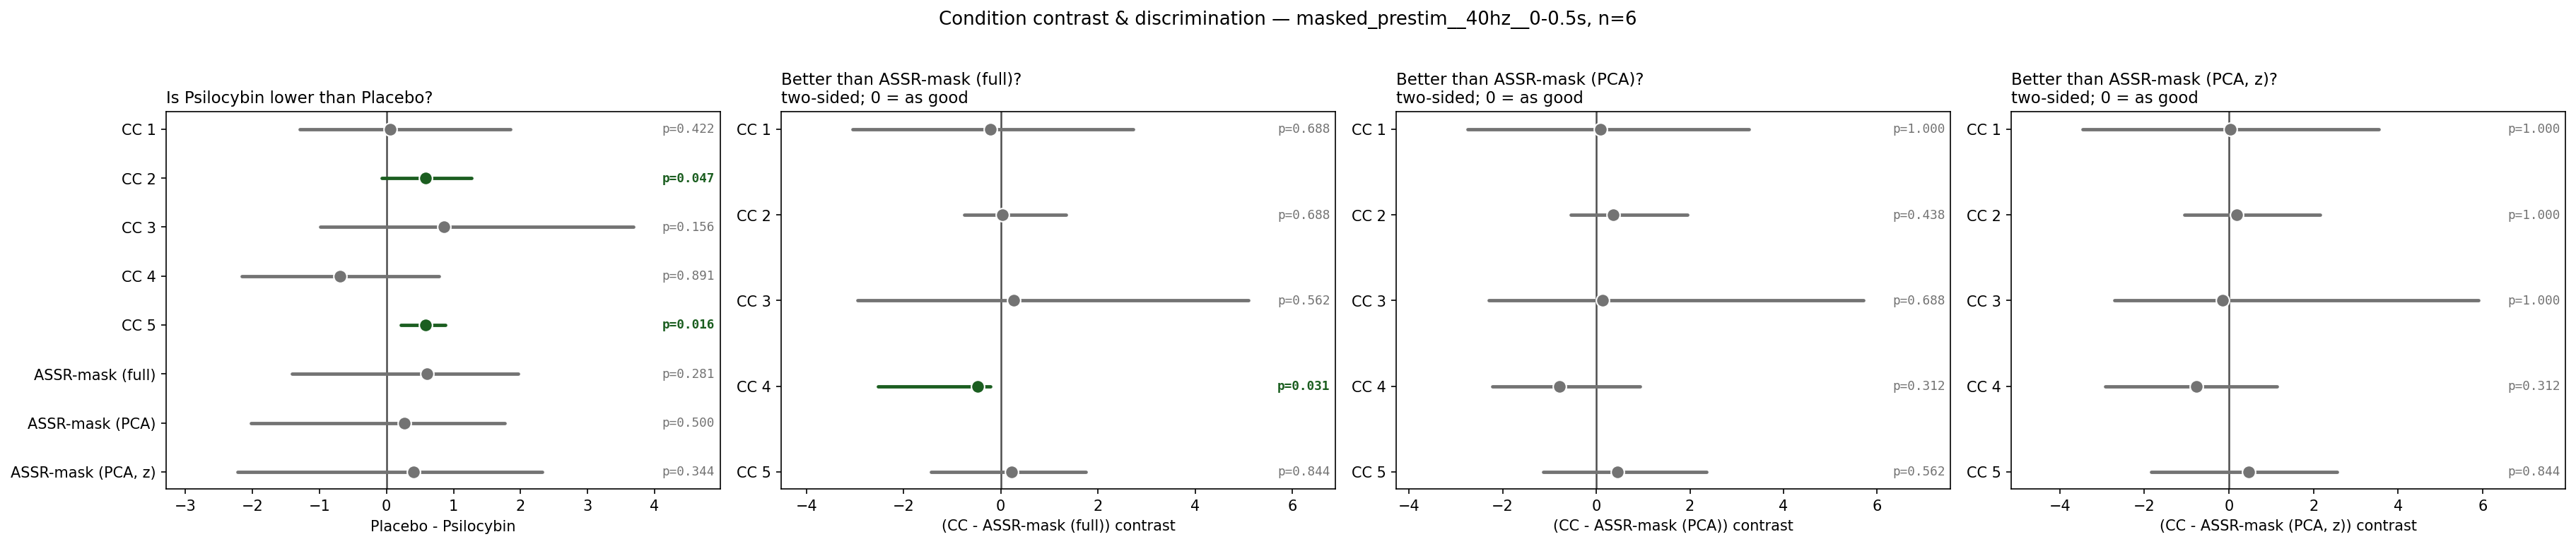

**06b-corrca-condition-comparison/JoinedSeparate_ASSR/broadband/corrca_snr_grid/pca_5/40hz/0-0.5s/pvalue_summary__prestim.png**

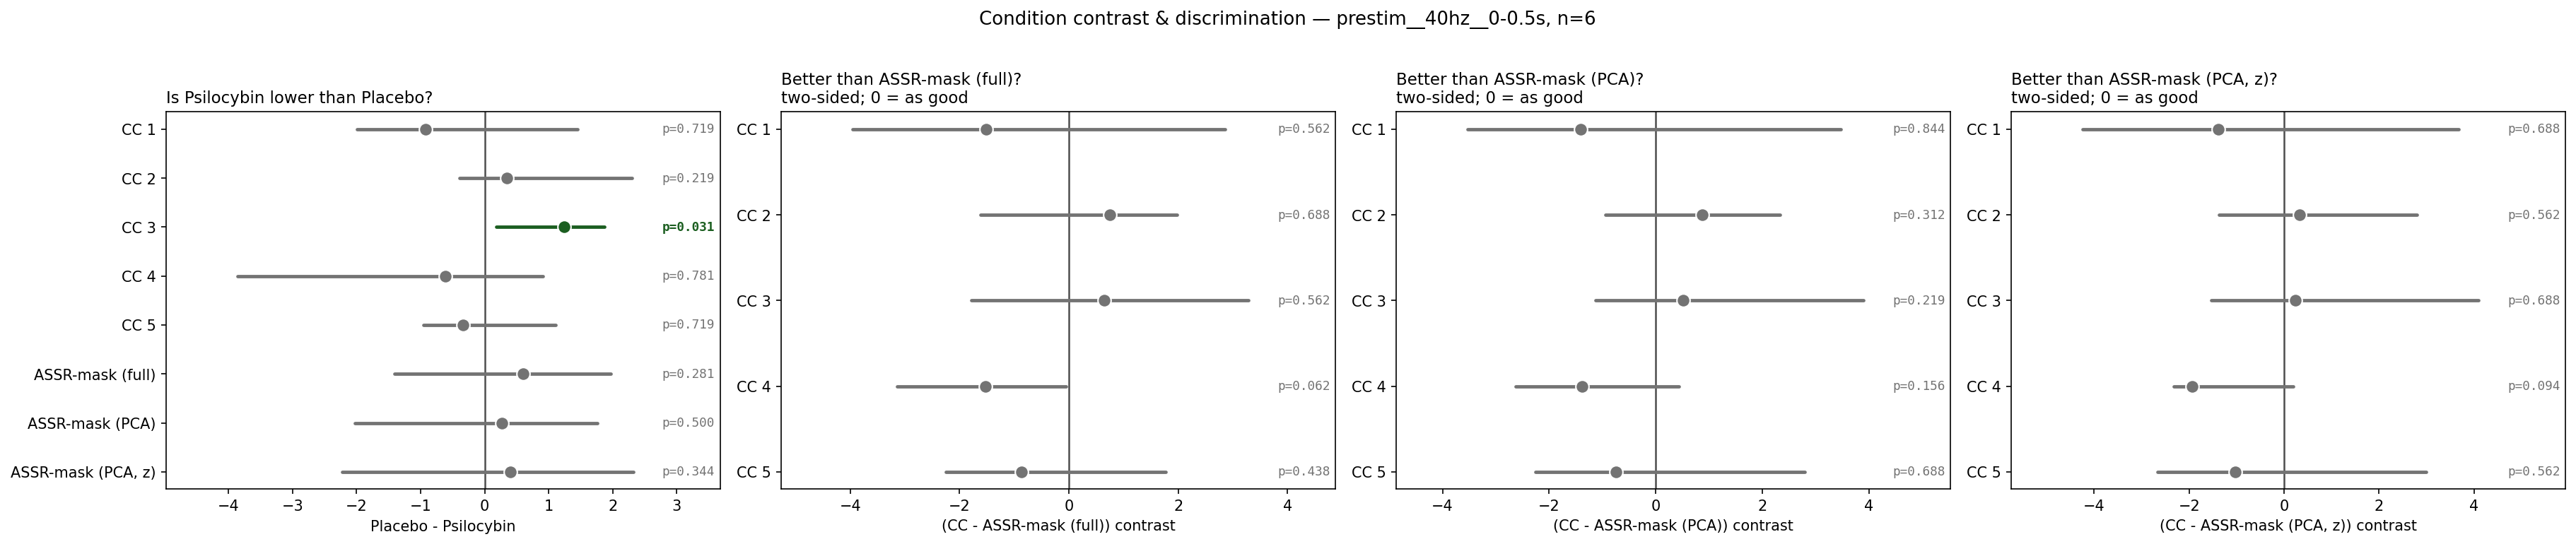

**06b-corrca-condition-comparison/JoinedSeparate_ASSR/broadband/corrca_snr_grid/pca_5/40hz/0-0.5s/snr_by_condition__masked_prestim.png**

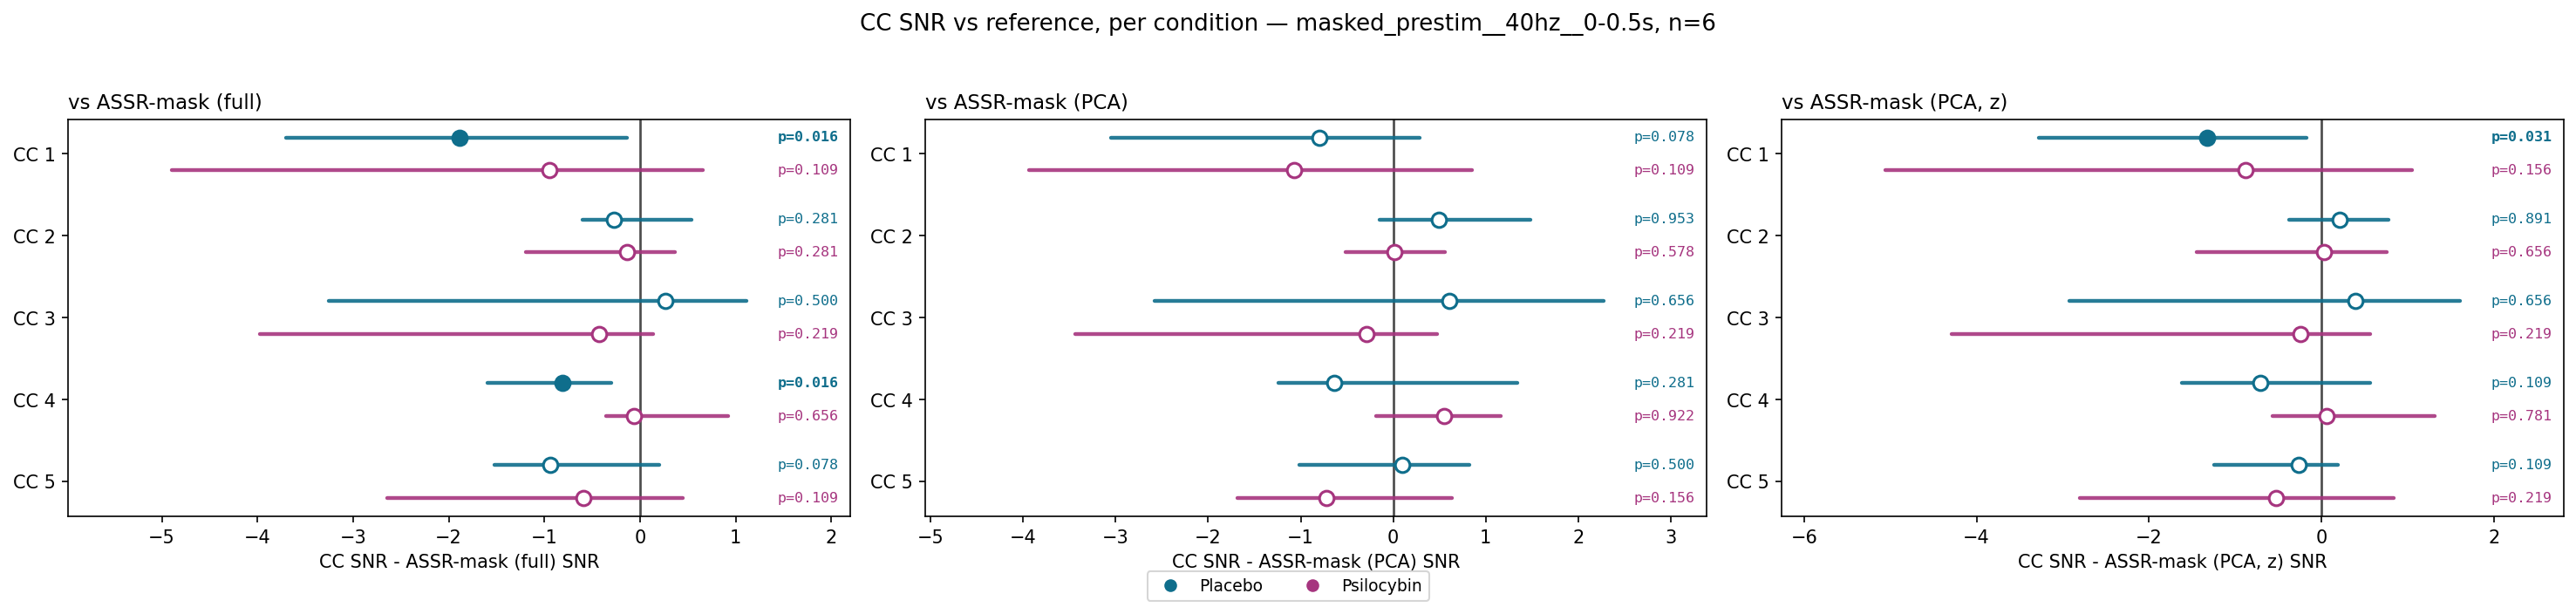

**06b-corrca-condition-comparison/JoinedSeparate_ASSR/broadband/corrca_snr_grid/pca_5/40hz/0-0.5s/snr_by_condition__prestim.png**

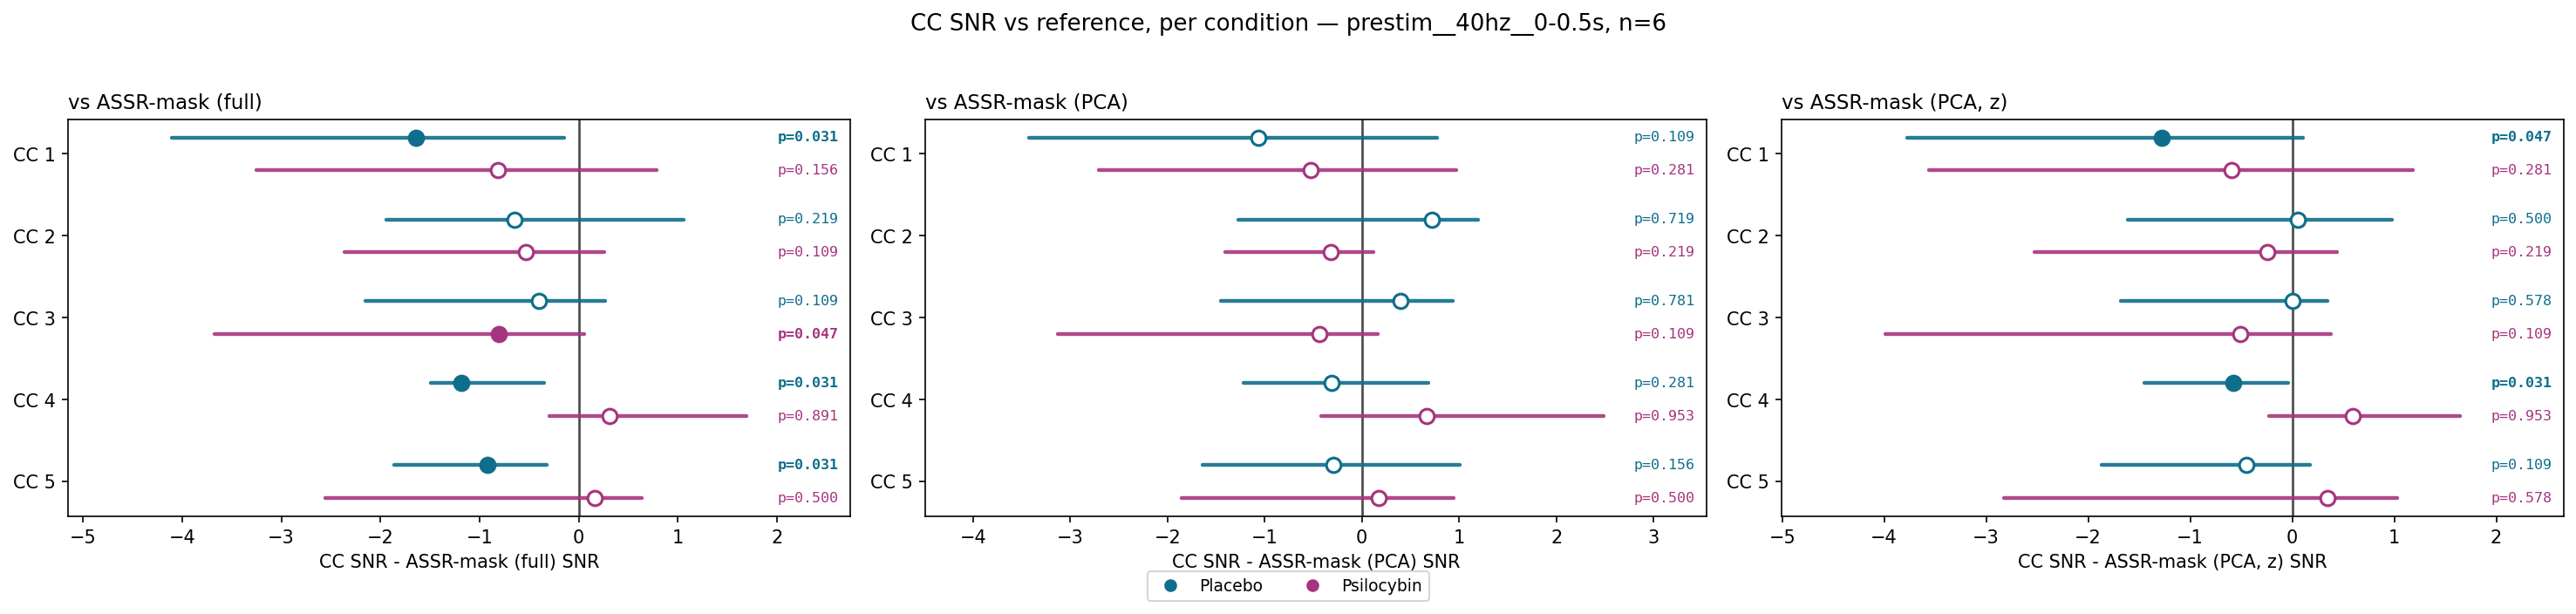

**06b-corrca-condition-comparison/JoinedSeparate_ASSR/broadband/corrca_snr_grid/pca_5/40hz/0-0.5s/trial_course_by_source__masked_prestim.png**

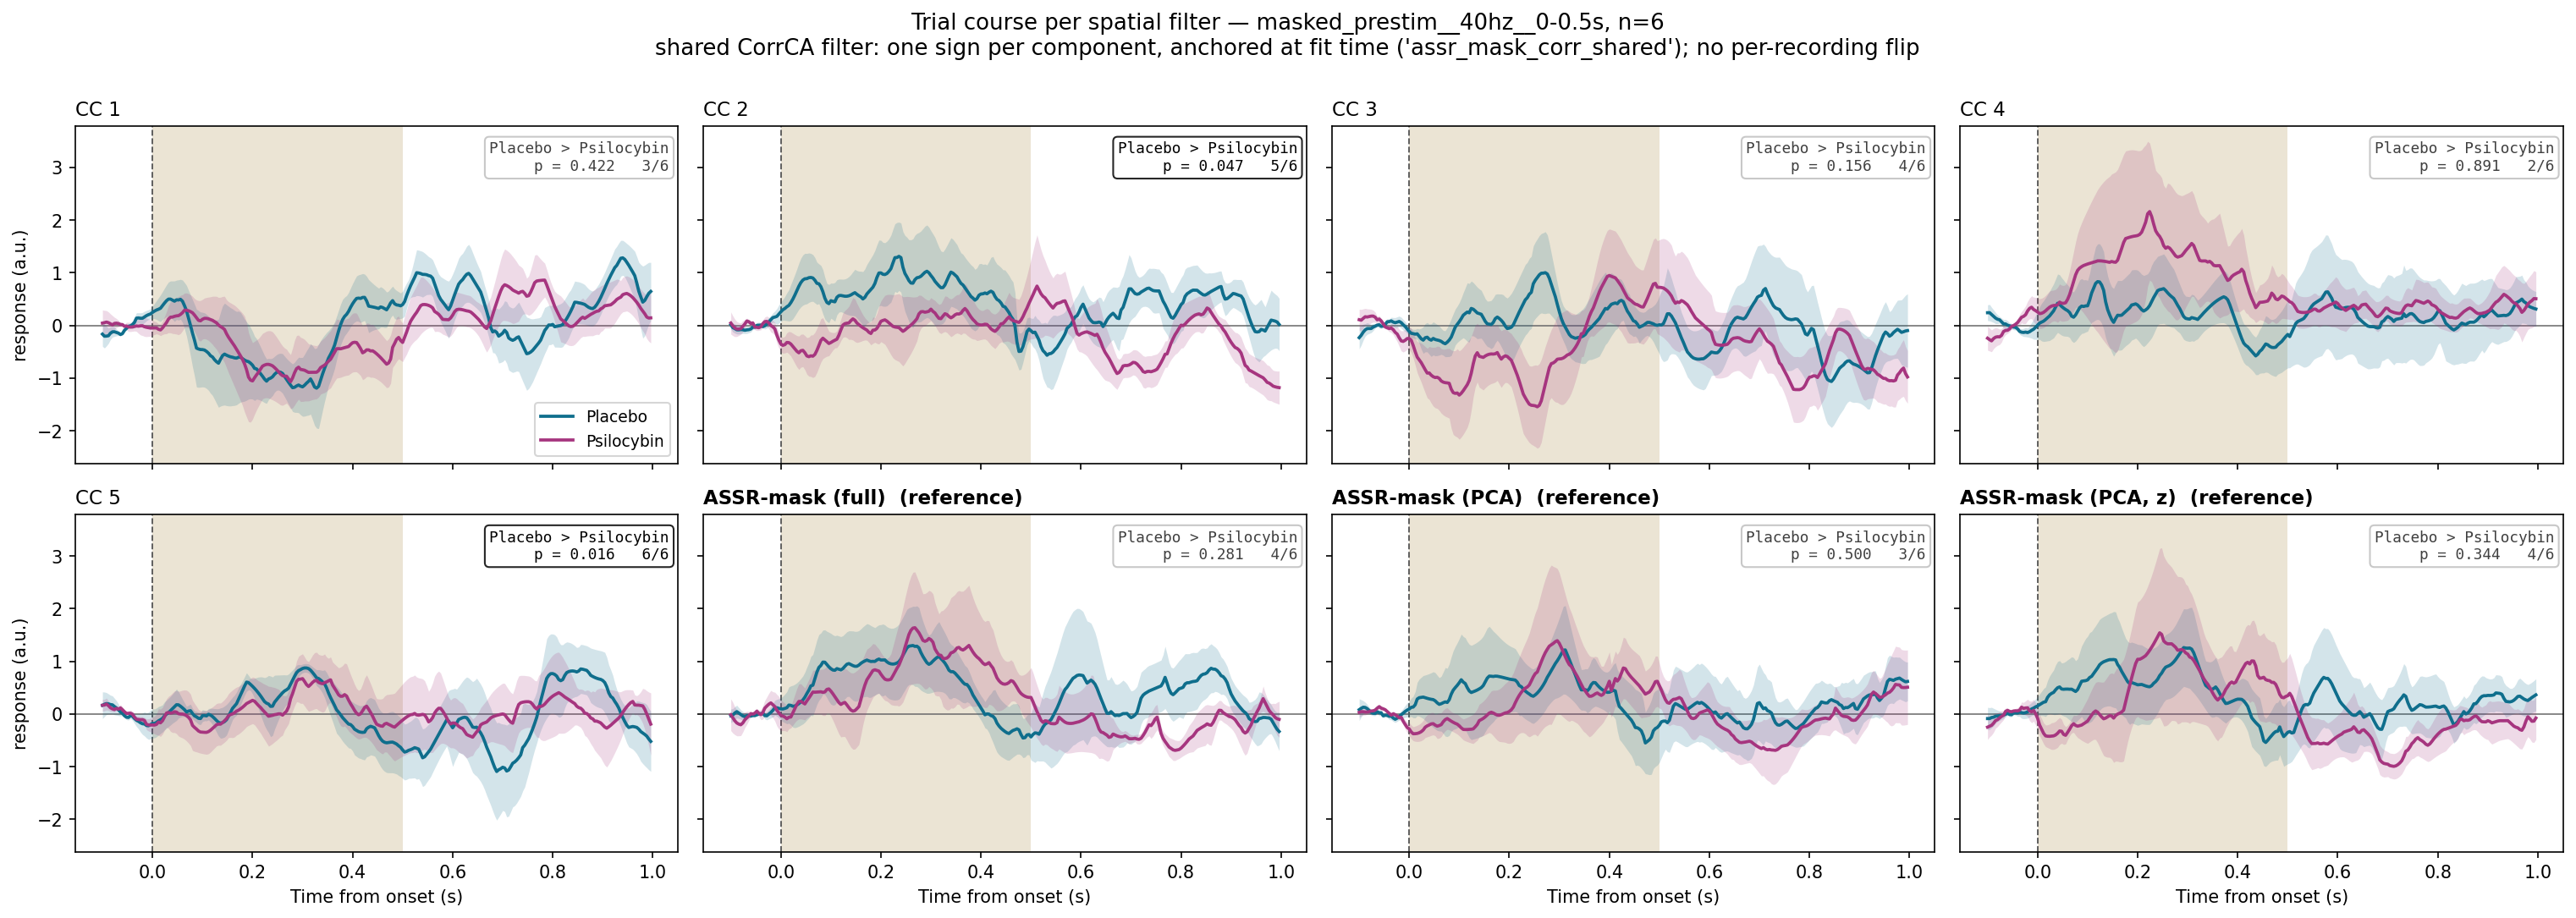

**06b-corrca-condition-comparison/JoinedSeparate_ASSR/broadband/corrca_snr_grid/pca_5/40hz/0-0.5s/trial_course_by_source__prestim.png**

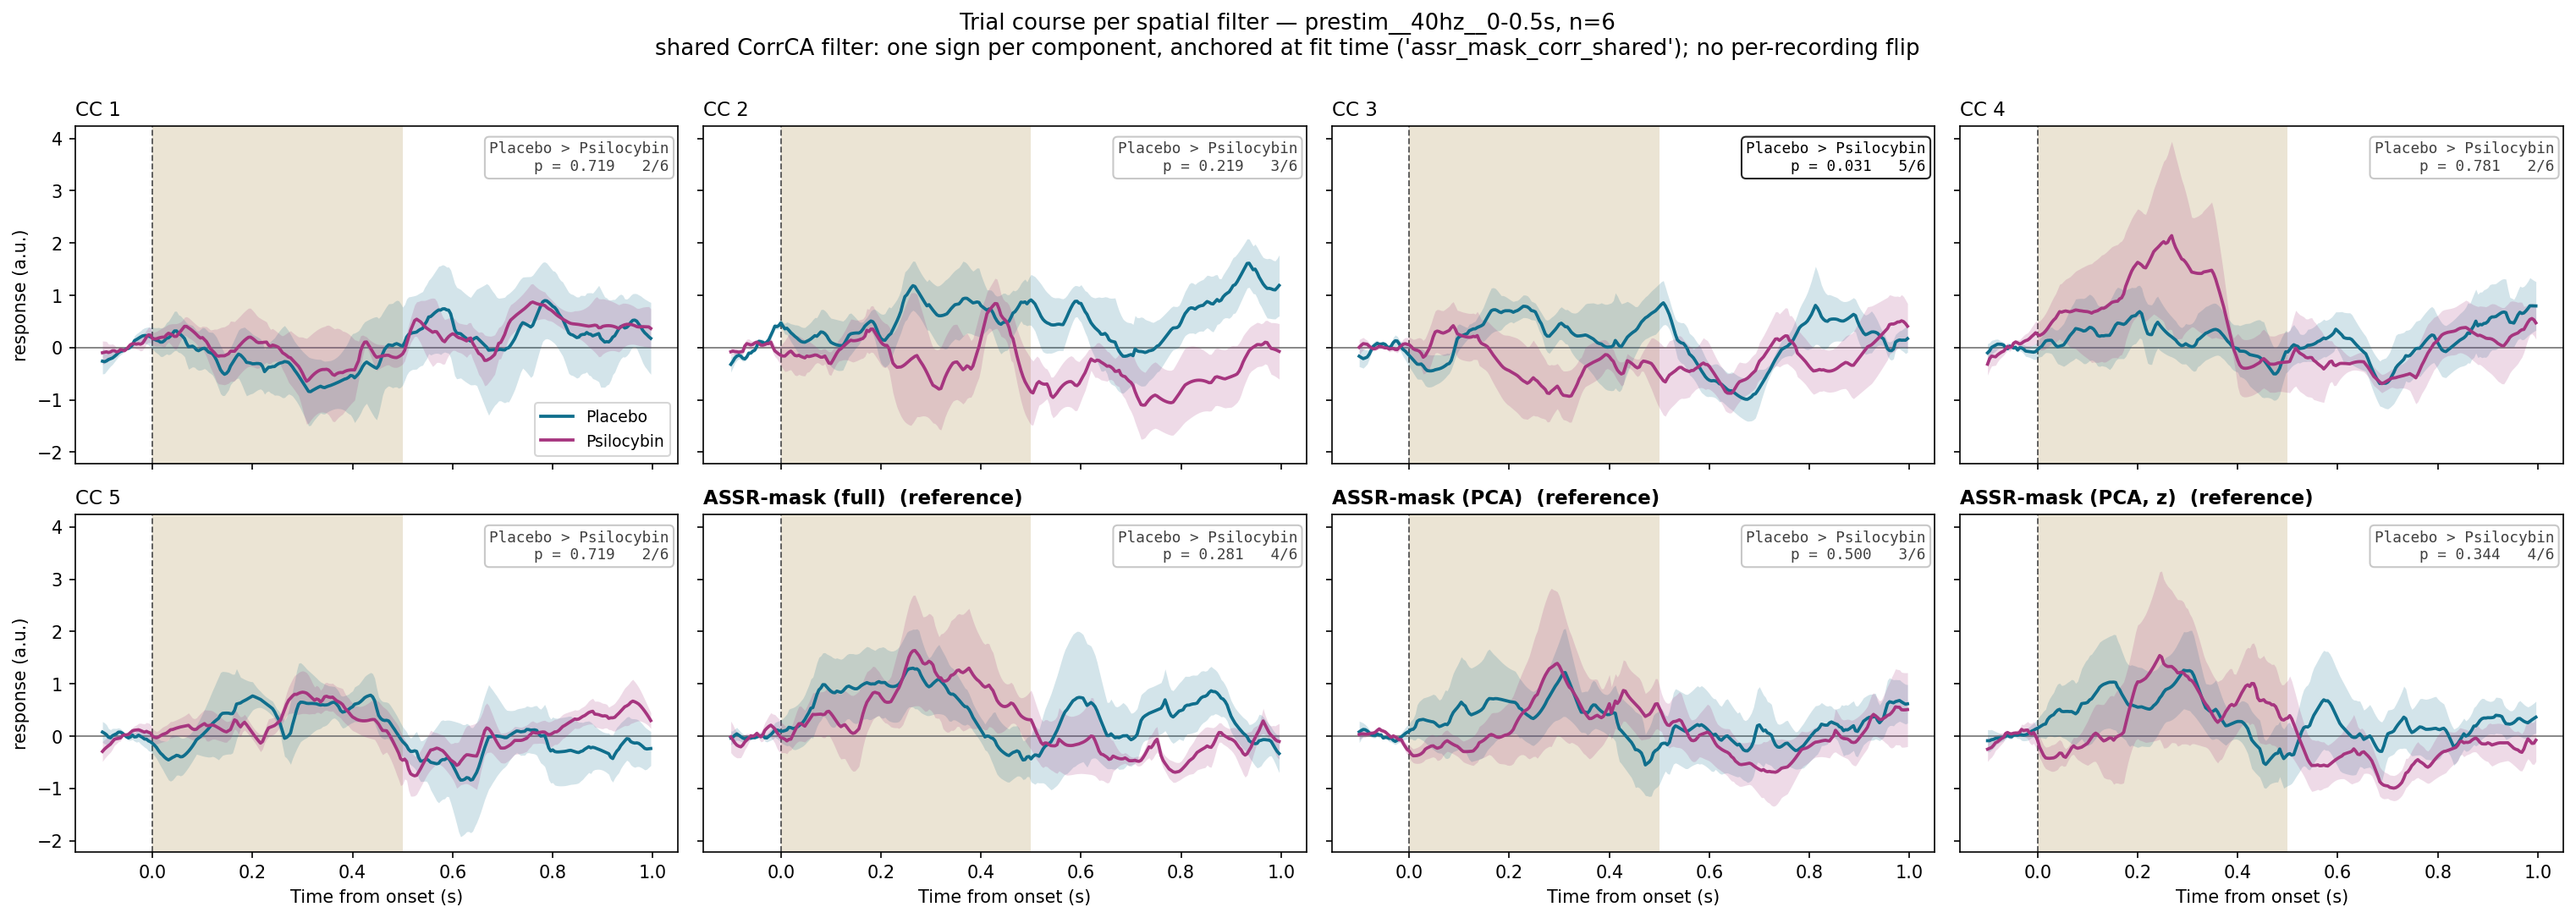

**06b-corrca-condition-comparison/JoinedSeparate_ASSR/broadband/corrca_snr_grid/pca_5/masked_filter_topomaps.png**

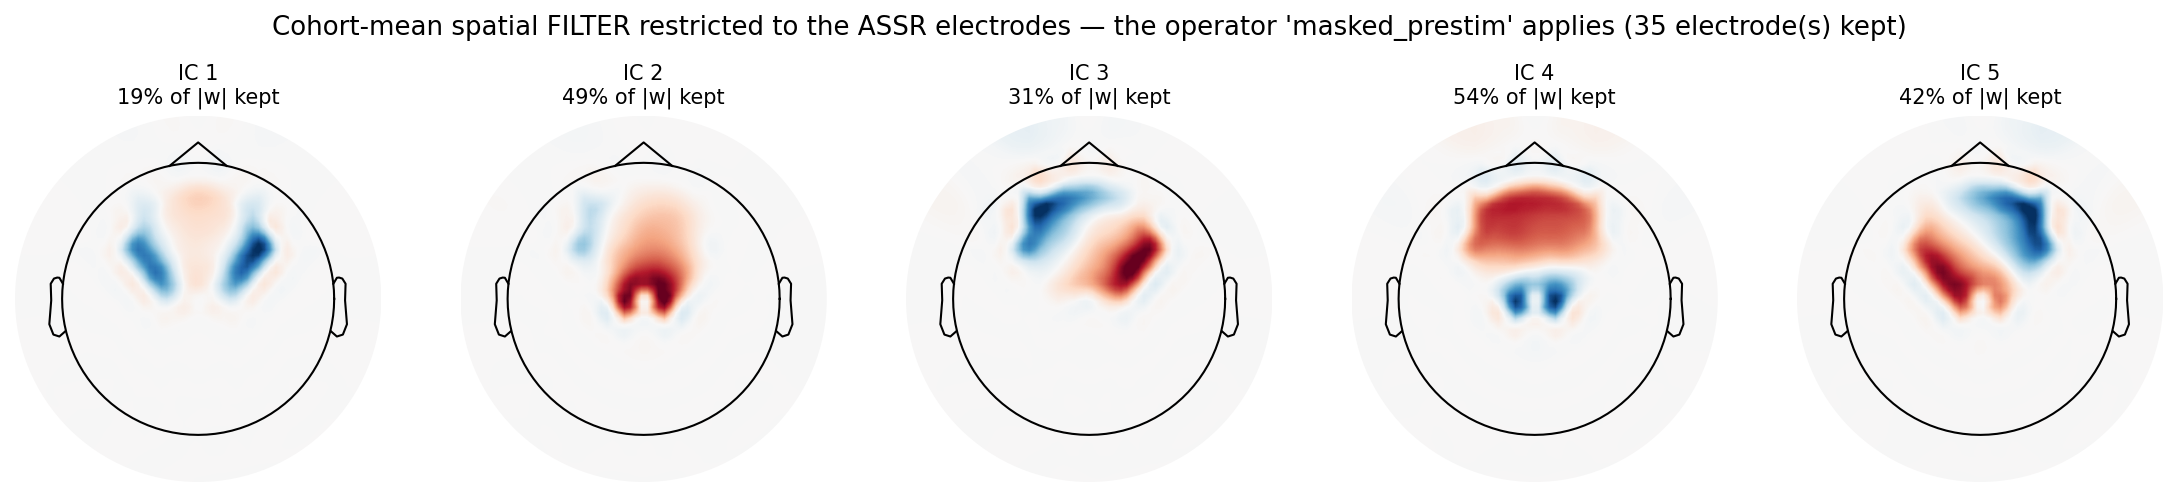

In [5]:
for png in sorted(PLOTS_DIR.rglob("*.png")):
    display(Markdown(f"**{png.relative_to(PLOTS_DIR)}**"))
    display(Image(filename=str(png)))